[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E7%BE%A4%E7%B5%84%E8%B3%87%E6%96%99%E5%92%8C%E7%BE%A4%E7%B5%84%E9%81%8B%E7%AE%97/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E8%8C%B6%E8%AA%9E%E6%99%82%E5%85%89_%E5%8F%B0%E5%8D%97%E4%BA%BA%E7%9C%9F%E7%9A%84%E6%84%9B%E5%85%A8%E7%B3%96%E5%97%8E.ipynb)

# 🧩 茶語時光：台南人真的愛全糖嗎？

> 🎯 **情境**：公司內部流傳很多「都市傳說」：台南人特別愛全糖、逢甲店晚上才是戰場、會員比較會花錢……新來的行銷總監說：「別再用猜的，拿數據來！」你手上有第一季 12 萬筆訂單明細，只要學會一招 **groupby（分組 → 計算 → 合併）**，就能一一驗證。

| 素材檔案 | 內容 |
| --- | --- |
| `訂單明細_2024Q1.csv` | 第一季約 12 萬筆訂單明細：時間、門市、品項、甜度、冰塊、數量、金額、是否會員、付款方式 |

> ⚠️ 「茶語時光」是課程虛構的品牌，資料為模擬資料；節日與颱風假的日期參考台灣實際情況，方便你對照生活經驗。

## 🗺️ 今日任務地圖

| 關卡 | 要回答的問題 |
| --- | --- |
| ⬜ 任務 1 | 各店成績單——營收、杯數、訂單數、客單價 |
| ⬜ 任務 2 | 傳說 1——台南人真的愛全糖嗎？ |
| ⬜ 任務 3 | 傳說 2——逢甲店晚上才是戰場？找出各店尖峰時段 |
| ⬜ 任務 4 | 傳說 3——會員比較會花錢嗎？ |
| ⬜ 任務 5 | pd.cut——把訂單分成「小額、中額、大額」 |
| ⬜ 任務 6 | 樞紐分析表——每家店的「招牌飲料」 |

**怎麼用這本 Notebook**：從上到下按 `Shift + Enter` 一格一格執行。每個任務都會先講「老闆想知道什麼」，再給程式，最後用 💡 **看懂結果** 告訴你這個數字代表什麼。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '訂單明細_2024Q1.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E7%BE%A4%E7%B5%84%E8%B3%87%E6%96%99%E5%92%8C%E7%BE%A4%E7%B5%84%E9%81%8B%E7%AE%97/%E7%BE%A4%E7%B5%84%E8%B3%87%E6%96%99%E5%92%8C%E7%BE%A4%E7%B5%84%E9%81%8B%E7%AE%97_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['訂單明細_2024Q1.csv']


In [ ]:
# --- 設定 Matplotlib 中文字型支援（Mac / Windows / Colab 通用）---
%pip install -q mplfonts

import glob, os
import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)   # 直接註冊 mplfonts 內附的字型，不改任何檔案
use_font("Noto Sans CJK SC")              # 套用思源黑體，負號也會一起處理

## 任務 1：各店成績單——營收、杯數、訂單數、客單價

**白話說明**：「依 ___ 分組，計算 ___ 的 ___」。注意：一筆訂單有好幾列（好幾個品項），**訂單數要用 `nunique` 數不重複的訂單編號**。

In [3]:
import pandas as pd

orders = pd.read_csv('訂單明細_2024Q1.csv', parse_dates=['訂單時間'])
print(orders.shape)
display(orders.head(3))

kpi = orders.groupby('門市').agg(營收=('金額', 'sum'),            # (新欄名, (原欄位, 計算方式))
                                 杯數=('數量', 'sum'),
                                 訂單數=('訂單編號', 'nunique'))   # 不重複的訂單編號數
kpi['客單價'] = (kpi['營收'] / kpi['訂單數']).round(1)            # 先加總、再相除
display(kpi.sort_values('營收', ascending=False))

(119948, 13)


,訂單編號,訂單時間,門市,品項,類別,尺寸,甜度,冰塊,數量,單價,金額,會員,付款方式
0,T240101000001,2024-01-01 18:36:29,台北信義店,珍珠奶茶,奶茶,中,微糖,微冰,1,55,55,N,街口支付
1,T240101000001,2024-01-01 18:36:29,台北信義店,多多綠,果茶,中,少糖,少冰,1,50,50,N,街口支付
2,T240101000001,2024-01-01 18:36:29,台北信義店,四季春青茶,純茶,中,半糖,少冰,1,35,35,N,街口支付


,營收,杯數,訂單數,客單價
門市,,,,
台中逢甲店,2172560,37577,17430,124.6
高雄巨蛋店,1761655,31787,15508,113.6
台北西門店,1751735,31381,15350,114.1
台北信義店,1532955,27937,12048,127.2
台南成大店,1521110,27017,14710,103.4


## 任務 2：傳說 1——台南人真的愛全糖嗎？

**白話說明**：依「門市 × 甜度」分組加總杯數，再把每家店換算成百分比——**一定要比「比例」**，因為每家店的總杯數不一樣。

In [4]:
sweet = orders.groupby(['門市', '甜度'])['數量'].sum().unstack('甜度')   # 門市 × 甜度 的杯數
sweet = sweet[['正常糖', '少糖', '半糖', '微糖', '無糖']]
sweet_pct = sweet.div(sweet.sum(axis=1), axis=0) * 100               # 每一列除以該店總杯數 → 百分比
display(sweet_pct.round(1))

甜度,正常糖,少糖,半糖,微糖,無糖
門市,,,,,
台中逢甲店,22.1,21.5,26.0,16.2,14.1
台北信義店,12.0,17.9,27.5,20.2,22.4
台北西門店,22.2,22.4,25.7,15.7,13.9
台南成大店,41.7,20.1,18.0,12.2,7.9
高雄巨蛋店,21.6,22.3,26.0,15.8,14.3


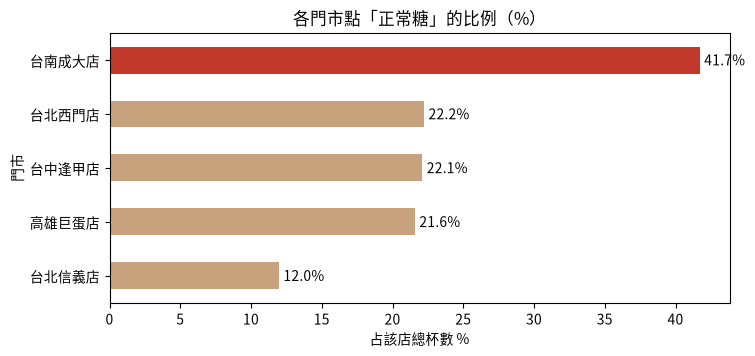

In [5]:
import matplotlib.pyplot as plt

full_sugar = sweet_pct['正常糖'].sort_values()                       # 各店「正常糖」占比，由小到大
colors = ['#C0392B' if s == '台南成大店' else '#C8A27C' for s in full_sugar.index]   # 台南用紅色凸顯
ax = full_sugar.plot.barh(color=colors, figsize=(8, 3.5), title='各門市點「正常糖」的比例（%）')
for i, v in enumerate(full_sugar):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center')                     # 在長條旁邊寫上數字
ax.set_xlabel('占該店總杯數 %')
plt.show()

> 💡 **看懂結果**：台南成大店點「正常糖」的比例是其他門市的 **2～3 倍**——傳說是真的！台北信義店（商辦區）則是「無糖」比例最高。
> 行銷建議：台南主打招牌甜飲，信義店可以優先試賣健康無糖新品。
>
> 🤖 **換你問 AI**：「請依門市與甜度分組加總杯數，換算成每家門市的百分比，並找出各門市最受歡迎的甜度。」

## 任務 3：傳說 2——逢甲店晚上才是戰場？找出各店尖峰時段

In [6]:
orders['小時'] = orders['訂單時間'].dt.hour
by_hour = orders.groupby(['門市', '小時'])['訂單編號'].nunique().unstack('門市')   # 小時 × 門市 的訂單數
display(by_hour)
print('\n各店尖峰時段：')
display(by_hour.idxmax().map(lambda h: f'{h}:00～{h + 1}:00'))       # idxmax：每一欄最大值出現在哪一個小時

門市,台中逢甲店,台北信義店,台北西門店,台南成大店,高雄巨蛋店
小時,,,,,
10,236,377,408,427,400
11,461,952,679,908,592
12,683,2217,1029,1460,985
13,887,1869,1248,1351,957
14,846,1327,1457,1084,927
15,1076,1474,1660,1387,1176
16,1293,1325,1643,1528,1426
17,1817,957,1610,1324,1343
18,2122,586,1628,1347,1636



各店尖峰時段：


門市
台中逢甲店    20:00～21:00
台北信義店    12:00～13:00
台北西門店    15:00～16:00
台南成大店    16:00～17:00
高雄巨蛋店    19:00～20:00
dtype: str

> 💡 **看懂結果**：信義店的尖峰在中午 12 點（上班族午休），逢甲店的尖峰在晚上 8 點（夜市人潮）——**同一個品牌，排班表應該完全不同**。

## 任務 4：傳說 3——會員比較會花錢嗎？

**白話說明**：明細是「一列一個品項」，要比較「每筆訂單花多少」，必須**先把同一筆訂單加總**（第一次 groupby），再依會員分組比較（第二次 groupby）。

In [7]:
per_order = orders.groupby(['訂單編號', '會員', '門市'], as_index=False)['金額'].sum()   # 第一次：每筆訂單的總金額
member = per_order.groupby('會員')['金額'].agg([('訂單數', 'count'), ('平均客單價', 'mean'),
                                              ('中位數', 'median'), ('最高', 'max')])     # 第二次：會員 vs. 非會員
display(member.round(1))

,訂單數,平均客單價,中位數,最高
會員,,,,
N,43461,106.1,85.0,545
Y,31585,130.7,115.0,615


> 💡 **看懂結果**：會員的平均客單價明顯高於非會員（約多 25 元），中位數也比較高——**會員比較會花錢是真的**，推廣會員制度值得投資。

## 任務 5：pd.cut——把訂單分成「小額、中額、大額」

In [8]:
per_order['金額級距'] = pd.cut(per_order['金額'], bins=[0, 80, 160, 10_000],
                             labels=['小額(≤80)', '中額(81-160)', '大額(>160)'])
level = pd.crosstab(per_order['門市'], per_order['金額級距'], normalize='index') * 100   # 各店訂單的級距占比 %
display(level.round(1))

金額級距,小額(≤80),中額(81-160),大額(>160)
門市,,,
台中逢甲店,36.2,37.3,26.4
台北信義店,35.0,35.8,29.2
台北西門店,42.4,35.6,22.1
台南成大店,50.4,32.3,17.2
高雄巨蛋店,42.9,35.5,21.6


> 💡 **看懂結果**：信義店（辦公室團購）與逢甲店（朋友揪團逛夜市）的大額訂單比例最高；台南成大店以學生為主，一半是單杯小額訂單。**滿額優惠要針對信義、逢甲設計，台南則適合第二杯折扣。**
>
> 🤖 **換你問 AI**：「請先把訂單明細依訂單編號加總成每筆訂單金額，再用 pd.cut 分成 ≤80、81–160、>160 三級，計算各門市的級距占比。」

## 任務 6：樞紐分析表——每家店的「招牌飲料」

**白話說明**：每家店賣最多的都是珍珠奶茶（它本來就是全公司最暢銷的），這樣看不出特色。改看「**偏好指數**」＝某品項在這家店的占比 ÷ 全公司的占比，大於 1 代表「這家店的客人特別愛」。

In [9]:
pivot = orders.pivot_table(index='品項', columns='門市', values='數量', aggfunc='sum', margins=True, margins_name='合計')
display(pivot.sort_values('合計', ascending=False))

share = orders.groupby(['門市', '品項'])['數量'].sum()
share = share / share.groupby(level='門市').transform('sum')              # transform：每個品項除以「自己門市」的總杯數 → 店內占比
overall = orders.groupby('品項')['數量'].sum() / orders['數量'].sum()     # 全公司占比
lift = (share / overall).unstack('門市')                                 # 偏好指數 = 店內占比 ÷ 全公司占比（> 1 代表比平均更受歡迎）
display(lift.round(2))
print('\n偏好指數最高的品項：\n', lift.idxmax())
print('\n排除季節性飲料後的各店招牌：\n', lift.drop(index=['熱可可', '芒果冰沙']).idxmax())

門市,台中逢甲店,台北信義店,台北西門店,台南成大店,高雄巨蛋店,合計
品項,,,,,,
合計,37577.0,27937.0,31381.0,27017.0,31787.0,155699
珍珠奶茶,8132.0,6176.0,9460.0,6388.0,7109.0,37265
四季春青茶,5595.0,4620.0,4136.0,3831.0,4724.0,22906
黑糖珍珠鮮奶,7411.0,3674.0,3813.0,3607.0,3923.0,22428
鮮奶綠,4142.0,4887.0,3464.0,3064.0,3587.0,19144
冬瓜檸檬,4092.0,2570.0,3118.0,4281.0,3573.0,17634
檸檬紅茶,4290.0,2602.0,3217.0,2957.0,3502.0,16568
多多綠,3591.0,2092.0,2802.0,2473.0,4611.0,15569
熱可可,190.0,1275.0,1332.0,19.0,NaN,2816


門市,台中逢甲店,台北信義店,台北西門店,台南成大店,高雄巨蛋店
品項,,,,,
冬瓜檸檬,0.96,0.81,0.88,1.40,0.99
四季春青茶,1.01,1.12,0.90,0.96,1.01
多多綠,0.96,0.75,0.89,0.92,1.45
檸檬紅茶,1.07,0.88,0.96,1.03,1.04
熱可可,0.28,2.52,2.35,0.04,NaN
珍珠奶茶,0.90,0.92,1.26,0.99,0.93
芒果冰沙,0.41,0.17,0.14,1.67,2.71
鮮奶綠,0.90,1.42,0.90,0.92,0.92
黑糖珍珠鮮奶,1.37,0.91,0.84,0.93,0.86



偏好指數最高的品項：
 門市
台中逢甲店    黑糖珍珠鮮奶
台北信義店       熱可可
台北西門店       熱可可
台南成大店      芒果冰沙
高雄巨蛋店      芒果冰沙
dtype: str

排除季節性飲料後的各店招牌：
 門市
台中逢甲店    黑糖珍珠鮮奶
台北信義店       鮮奶綠
台北西門店      珍珠奶茶
台南成大店      冬瓜檸檬
高雄巨蛋店       多多綠
dtype: str


> 💡 **看懂結果**：
> - 偏好指數最高的竟然是季節飲料：台北比較冷 → 熱可可特別好賣；台南、高雄比較熱 → 芒果冰沙特別好賣。**氣候差異會直接反映在菜單上。**
> - 排除季節品後，每家店的招牌就很清楚了：逢甲是黑糖珍珠鮮奶、信義是鮮奶綠、西門是珍珠奶茶、台南是冬瓜檸檬、高雄是多多綠——可以依門市規劃不同的主打商品。

---

## ✍️ 換你動手：練習區

每一題都有三格：**① 半成品程式**（把 `___` 換成正確的程式）→ **② ✅ 檢查格**（自動告訴你對不對）→ **③ 🔑 參考解答**（折疊起來，先自己試）。

> 看到 `NameError: name '___' is not defined` 不用緊張，那代表還有空格沒填。

In [10]:
# @title 🧰 練習檢查小幫手（執行一次就好，不用看懂裡面的程式）
import math
import numpy as np
import pandas as pd


def _same(ans, expected, ordered=False):
    if isinstance(expected, (pd.DataFrame, pd.Series)):
        if type(ans) is not type(expected):
            return False
        try:
            assert_equal = pd.testing.assert_frame_equal if isinstance(expected, pd.DataFrame) else pd.testing.assert_series_equal
            if not ordered:
                ans, expected = ans.sort_index(), expected.sort_index()
            assert_equal(ans, expected, check_names=False, check_dtype=False,
                         check_index_type=False, check_exact=False, rtol=1e-3, atol=0.06,
                         **({'check_column_type': False} if isinstance(expected, pd.DataFrame) else {}))
            return True
        except (AssertionError, TypeError, ValueError):
            return False
    if isinstance(expected, np.ndarray):
        return np.asarray(ans).shape == expected.shape and np.allclose(np.asarray(ans, dtype=float), expected, atol=0.06)
    if isinstance(expected, (int, float, np.number)) and not isinstance(expected, bool):
        try:
            return math.isclose(float(ans), float(expected), rel_tol=1e-3, abs_tol=0.06)
        except (TypeError, ValueError):
            return False
    if isinstance(expected, (list, tuple, set)):
        return list(ans) == list(expected) if not isinstance(expected, set) else set(ans) == expected
    return ans == expected


def check(name, expected, ordered=False):
    """比對學生的變數 name 和正確答案 expected，印出 ✅ 或 ❌；ordered=True 時連排列順序也要一樣。"""
    if name not in globals():
        print(f'⏳ 還找不到變數 {name}：請先把上一格的 ___ 填好並執行')
        return
    ans = globals()[name]
    if _same(ans, expected, ordered):
        print(f'✅ {name} 答對了！')
        return
    print(f'❌ {name} 還不對，再檢查看看：')
    if type(ans) is not type(expected):
        print(f'   型態不同：你的是 {type(ans).__name__}，應該是 {type(expected).__name__}')
    elif hasattr(expected, 'shape') and getattr(ans, 'shape', None) != expected.shape:
        print(f'   大小不同：你的是 {ans.shape}，應該是 {expected.shape}')
    else:
        print('   型態和大小都對了，是數值' + ('或排列順序' if ordered else '') + '不一樣——檢查一下篩選條件或計算方式')


print('🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格')

🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格


### ✍️ 練習 1：各門市的付款方式占比（%），哪家店最常用現金？

<details><summary>💡 卡住了？點我看提示</summary>

付款方式是「一筆訂單」一個，所以先 `drop_duplicates('訂單編號')`；`pd.crosstab(..., normalize='index')` 會把每一列換算成比例。

</details>

In [ ]:
# ✏️ 練習 1：把 ___ 換成正確的程式，再按執行
one_row = orders.drop_duplicates(___)              # 一筆訂單只留一列
pay = pd.crosstab(one_row['門市'], one_row['付款方式'], normalize=___) * 100
cash_store = pay['現金'].idxmax()
display(pay.round(1))
print('最常用現金：', cash_store)

In [ ]:
# @title ✅ 執行這格，檢查練習 1
_o = orders.drop_duplicates('訂單編號')
check('pay', pd.crosstab(_o['門市'], _o['付款方式'], normalize='index') * 100)

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
one_row = orders.drop_duplicates('訂單編號')
pay = pd.crosstab(one_row['門市'], one_row['付款方式'], normalize='index') * 100
cash_store = pay['現金'].idxmax()
display(pay.round(1))
print('最常用現金：', cash_store)
```

</details>

### ✍️ 練習 2：熱飲在 1～3 月之間有什麼變化？

<details><summary>💡 卡住了？點我看提示</summary>

先用 `.dt.month` 做出「月份」欄，再「依月份 × 類別分組，加總數量」，`unstack('類別')` 把類別搬到欄位。

</details>

In [ ]:
# ✏️ 練習 2：把 ___ 換成正確的程式，再按執行
orders['月份'] = orders['訂單時間'].dt.___
hot_drink = orders.groupby(['月份', ___])['數量'].sum().unstack('類別')['熱飲']
display(hot_drink)

In [ ]:
# @title ✅ 執行這格，檢查練習 2
check('hot_drink', orders.groupby([orders['訂單時間'].dt.month, '類別'])['數量'].sum().unstack('類別')['熱飲'])

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
orders['月份'] = orders['訂單時間'].dt.month
hot_drink = orders.groupby(['月份', '類別'])['數量'].sum().unstack('類別')['熱飲']
display(hot_drink)
```

</details>

### ✍️ 練習 3：哪家店的客人最愛點大杯？

<details><summary>💡 卡住了？點我看提示</summary>

`(s == '大').mean()` 就是「大杯的比例」，因為 True 會被當成 1、False 當成 0。

</details>

In [ ]:
# ✏️ 練習 3：把 ___ 換成正確的程式，再按執行
large = orders.groupby(___)['尺寸'].apply(lambda s: (s == '大').mean() * 100)
display(large.round(1).sort_values(ascending=False))

In [ ]:
# @title ✅ 執行這格，檢查練習 3
check('large', orders.groupby('門市')['尺寸'].apply(lambda s: (s == '大').mean() * 100))

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
large = orders.groupby('門市')['尺寸'].apply(lambda s: (s == '大').mean() * 100)
display(large.round(1).sort_values(ascending=False))
```

</details>

---

## 🏆 任務完成！今天你用程式做到了這些事

- ✅ 任務 1：各店成績單——營收、杯數、訂單數、客單價
- ✅ 任務 2：傳說 1——台南人真的愛全糖嗎？
- ✅ 任務 3：傳說 2——逢甲店晚上才是戰場？找出各店尖峰時段
- ✅ 任務 4：傳說 3——會員比較會花錢嗎？
- ✅ 任務 5：pd.cut——把訂單分成「小額、中額、大額」
- ✅ 任務 6：樞紐分析表——每家店的「招牌飲料」

> 🎯 **帶走一句話**：程式只是工具，真正有價值的是你從資料裡找到的那句「所以我們應該……」。
> 把上面每個 💡 **看懂結果** 用自己的話寫成一句建議，就是一份可以交給老闆的報告。